In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mahakkhetan/fakenewsincidents-india-dataset-v1-xls/fakenewsincidents_india_dataset_v1.xls


In [3]:

# 1. IMPORT LIBRARIES AND LOAD DATASET


import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Find the uploaded Excel dataset in Kaggle inputs
for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        if filename.lower().endswith((".xls", ".xlsx")):
            print(os.path.join(dirname, filename))



/kaggle/input/datasets/mahakkhetan/fakenewsincidents-india-dataset-v1-xls/fakenewsincidents_india_dataset_v1.xls


In [4]:

# Replace the path below with the exact path printed above
file_path = "/kaggle/input/datasets/mahakkhetan/fakenewsincidents-india-dataset-v1-xls/fakenewsincidents_india_dataset_v1.xls"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))



Dataset loaded successfully!
Shape: (4802, 11)

Column names:
['fact_checking_website', 'fake_news_url', 'fake_news_date', 'fake_news_title', 'twitter_tweets', 'facebook_post', 'youtube_link', 'instagram_post', 'fake_news_images', 'Label', 'Content']

First 5 records:


,fact_checking_website,fake_news_url,fake_news_date,fake_news_title,twitter_tweets,facebook_post,youtube_link,instagram_post,fake_news_images,Label,Content
0,OpIndia,https://www.opindia.com/2016/06/congress-it-ce...,2016-06-02,Congress IT cell caught spreading fake pics of...,['https://twitter.com/c_aashish/status/7380196...,[],[],[],[],NaN,the congress social media team has often been ...
1,OpIndia,https://www.opindia.com/2016/12/journalist-wro...,2016-12-03,Journalist wrote fake report to prove rapes du...,['https://twitter.com/ArvindKejriwal/status/70...,[],[],[],[],NaN,in february this year many parts of haryana sa...
2,OpIndia,https://www.opindia.com/2016/10/did-pm-modi-ad...,2016-10-05,Fact-Check: Did PM Modi 'admit' that surgical ...,['https://twitter.com/vidya7281/status/7831651...,[],[],[],[],NaN,ever since india retaliated with the surgical ...
3,Alt News,https://www.altnews.in/12th-standard-student-w...,2016-04-10,A 12th Standard Student writes an open letter ...,[],"['http://www.facebook.com/altnews.in', 'https:...",[],[],[],Education,Error occurred while extracting content
4,Alt News,https://www.altnews.in/ani-news-misreports-fir...,2016-04-10,ANI News misreports firecrackers as dynamite s...,[],['https://www.facebook.com/sharer/sharer.php?u...,[],[],['http://www.altnews.in/wp-content/uploads/201...,Politics,in a very unfortunate incident over 100 people...



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4802 entries, 0 to 4801
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   fact_checking_website  4802 non-null   object        
 1   fake_news_url          4802 non-null   object        
 2   fake_news_date         4802 non-null   datetime64[ns]
 3   fake_news_title        4802 non-null   object        
 4   twitter_tweets         4802 non-null   object        
 5   facebook_post          4802 non-null   object        
 6   youtube_link           4802 non-null   object        
 7   instagram_post         4802 non-null   object        
 8   fake_news_images       4802 non-null   object        
 9   Label                  2001 non-null   object        
 10  Content                4801 non-null   object        
dtypes: datetime64[ns](1), object(10)
memory usage: 412.8+ KB

Missing values:


,Missing Values
fact_checking_website,0
fake_news_url,0
fake_news_date,0
fake_news_title,0
twitter_tweets,0
facebook_post,0
youtube_link,0
instagram_post,0
fake_news_images,0
Label,2801


In [5]:

# Clean column names
df.columns = df.columns.str.strip()

# Remove duplicate records
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# Convert date column to datetime
df["fake_news_date"] = pd.to_datetime(
    df["fake_news_date"], errors="coerce"
)

# Check missing values
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing.sort_values("Missing Percentage", ascending=False))

# Check data types and dataset size
print("Dataset shape after removing duplicates:", df.shape)
print("\nData types:")
print(df.dtypes)

# Check article text quality
df["Content"] = df["Content"].fillna("").astype(str)
df["fake_news_title"] = df["fake_news_title"].fillna("").astype(str)

df["content_length"] = df["Content"].str.len()
df["word_count"] = df["Content"].str.split().str.len()

print("\nArticle text statistics:")
display(df[["content_length", "word_count"]].describe().round(2))

print("\nRecords with empty article content:",
      (df["Content"].str.strip() == "").sum())


Duplicate rows: 151


,Missing Count,Missing Percentage
Label,2650,56.98
Content,1,0.02
fact_checking_website,0,0.00
fake_news_date,0,0.00
fake_news_url,0,0.00
fake_news_title,0,0.00
twitter_tweets,0,0.00
youtube_link,0,0.00
facebook_post,0,0.00
fake_news_images,0,0.00


Dataset shape after removing duplicates: (4651, 11)

Data types:
fact_checking_website            object
fake_news_url                    object
fake_news_date           datetime64[ns]
fake_news_title                  object
twitter_tweets                   object
facebook_post                    object
youtube_link                     object
instagram_post                   object
fake_news_images                 object
Label                            object
Content                          object
dtype: object

Article text statistics:


,content_length,word_count
count,4651.00,4651.00
mean,2996.99,525.54
std,2051.17,354.00
min,0.00,0.00
25%,1845.00,329.00
50%,2535.00,447.00
75%,3445.50,601.00
max,30022.00,5294.00



Records with empty article content: 1


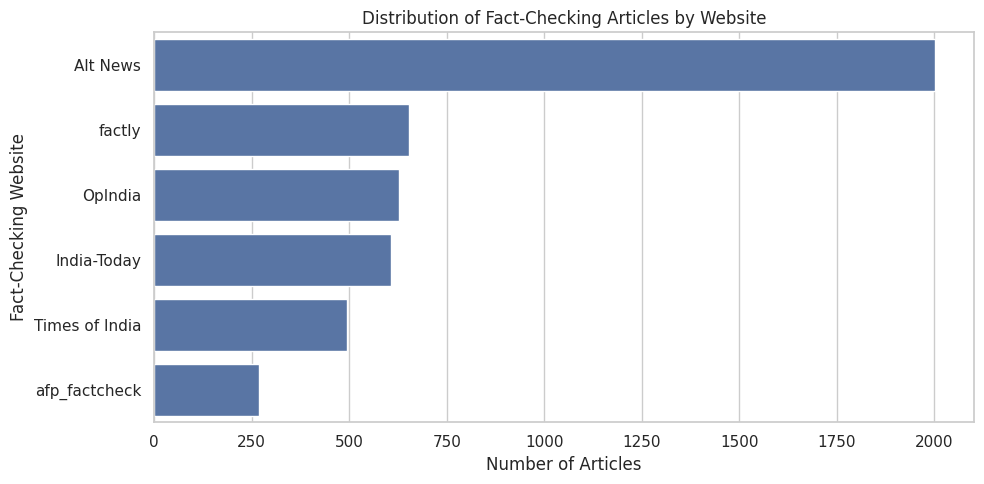

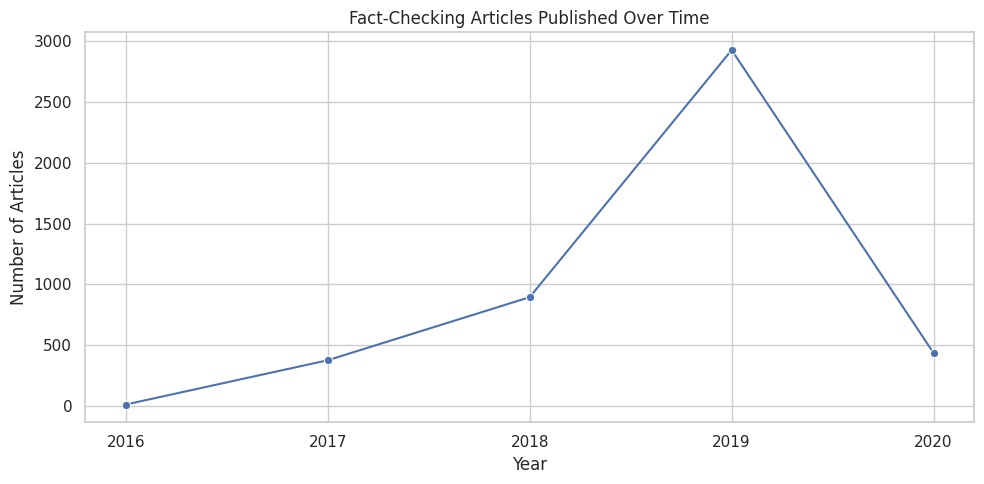

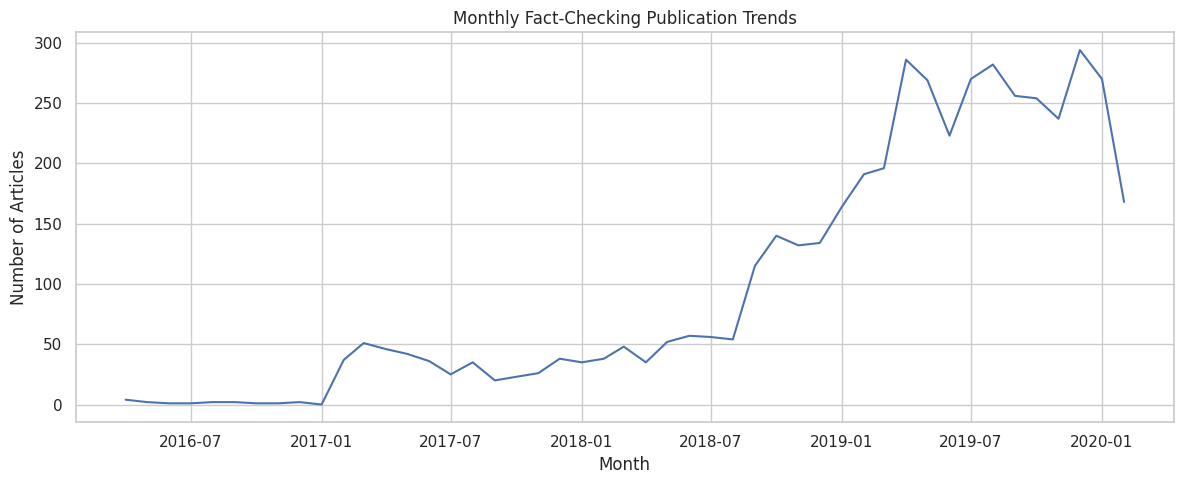

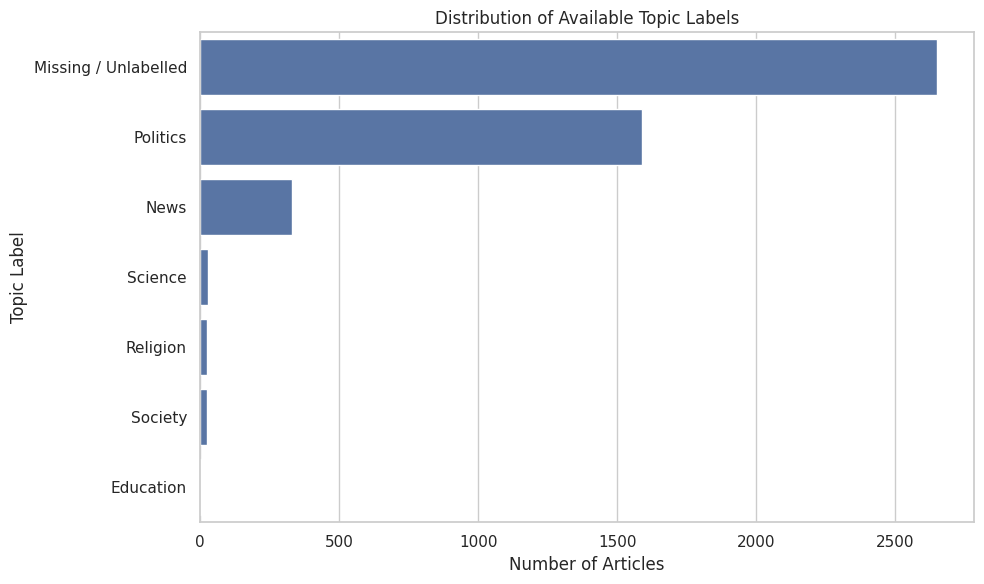

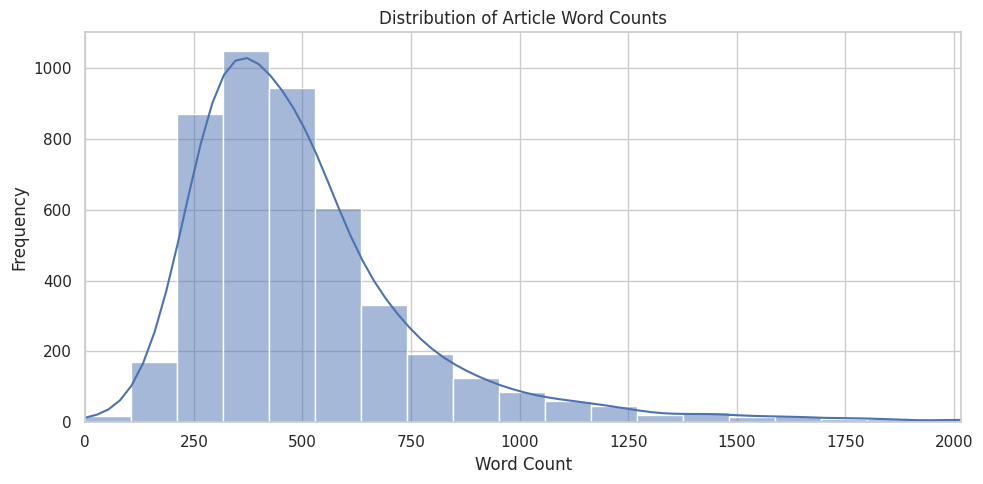

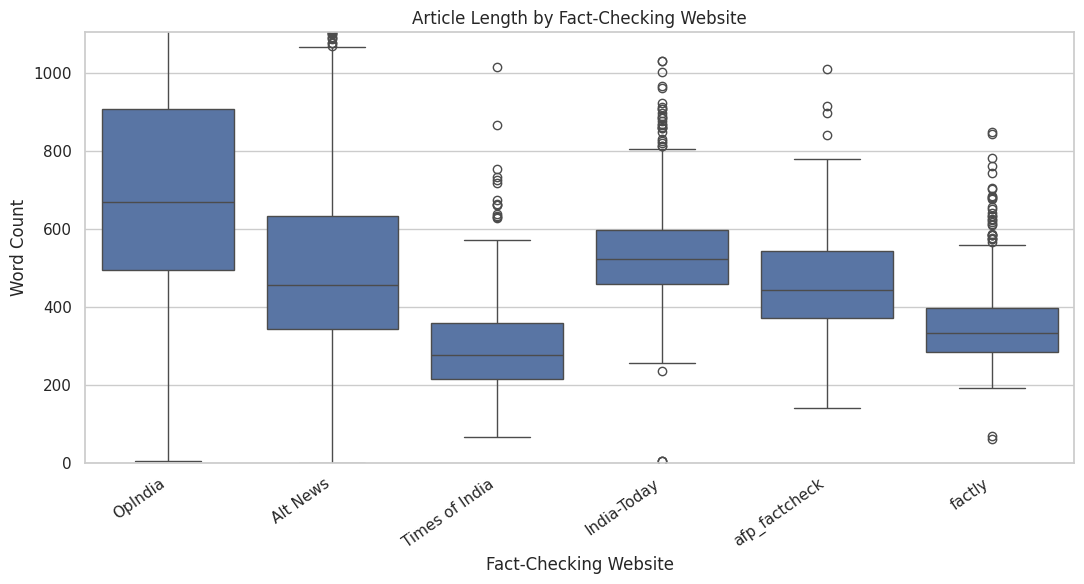

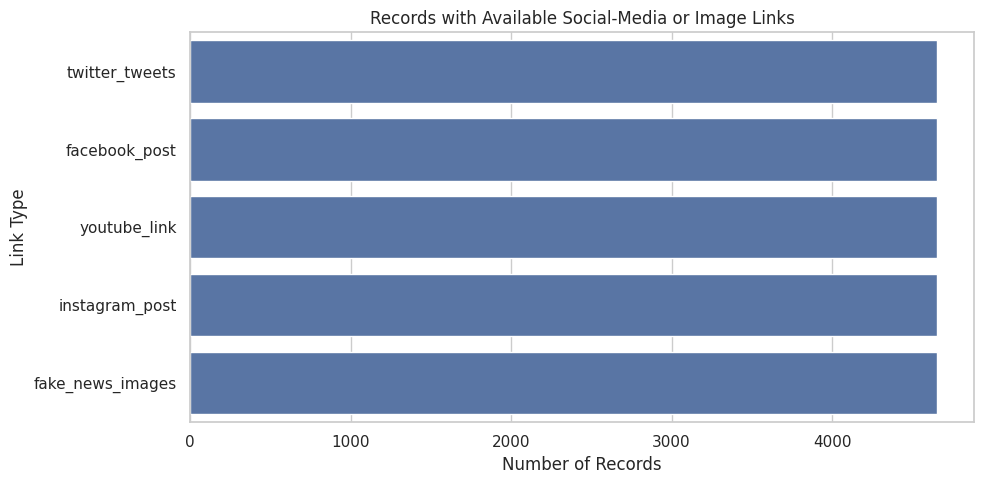

Articles by website:


,Article Count
fact_checking_website,
Alt News,2002
factly,652
OpIndia,627
India-Today,608
Times of India,494
afp_factcheck,268


Yearly publication counts:


,Article Count
year,
2016,16
2017,379
2018,896
2019,2922
2020,438


Article word-count statistics:


,Word Count
count,4651.000000
mean,525.536874
std,354.002362
min,0.000000
25%,329.000000
50%,447.000000
75%,601.000000
max,5294.000000


Percentage of records with each social-media/image link:


,Available (%)
twitter_tweets,100.0
facebook_post,100.0
youtube_link,100.0
instagram_post,100.0
fake_news_images,100.0


In [6]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# 1. Fact-checking articles by website
plt.figure(figsize=(10, 5))
outlet_counts = df["fact_checking_website"].value_counts()
sns.barplot(x=outlet_counts.values, y=outlet_counts.index)
plt.title("Distribution of Fact-Checking Articles by Website")
plt.xlabel("Number of Articles")
plt.ylabel("Fact-Checking Website")
plt.tight_layout()
plt.show()

# 2. Publication trends by year
yearly_counts = (
    df.dropna(subset=["fake_news_date"])
      .assign(year=lambda x: x["fake_news_date"].dt.year)
      .groupby("year")
      .size()
)

plt.figure(figsize=(10, 5))
sns.lineplot(x=yearly_counts.index, y=yearly_counts.values, marker="o")
plt.title("Fact-Checking Articles Published Over Time")
plt.xlabel("Year")
plt.ylabel("Number of Articles")
plt.xticks(yearly_counts.index)
plt.tight_layout()
plt.show()

# 3. Monthly publication trends
monthly_counts = (
    df.dropna(subset=["fake_news_date"])
      .set_index("fake_news_date")
      .resample("MS")
      .size()
)

plt.figure(figsize=(12, 5))
sns.lineplot(x=monthly_counts.index, y=monthly_counts.values)
plt.title("Monthly Fact-Checking Publication Trends")
plt.xlabel("Month")
plt.ylabel("Number of Articles")
plt.tight_layout()
plt.show()

# 4. Topic label distribution
if "Label" in df.columns:
    topic_counts = df["Label"].fillna("Missing / Unlabelled").value_counts().head(15)

    plt.figure(figsize=(10, 6))
    sns.barplot(x=topic_counts.values, y=topic_counts.index)
    plt.title("Distribution of Available Topic Labels")
    plt.xlabel("Number of Articles")
    plt.ylabel("Topic Label")
    plt.tight_layout()
    plt.show()

# 5. Article text length distribution
plt.figure(figsize=(10, 5))
sns.histplot(df["word_count"], bins=50, kde=True)
plt.title("Distribution of Article Word Counts")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.xlim(0, df["word_count"].quantile(0.99))
plt.tight_layout()
plt.show()

# 6. Compare article lengths across outlets
plt.figure(figsize=(11, 6))
sns.boxplot(data=df, x="fact_checking_website", y="word_count")
plt.title("Article Length by Fact-Checking Website")
plt.xlabel("Fact-Checking Website")
plt.ylabel("Word Count")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, df["word_count"].quantile(0.95))
plt.tight_layout()
plt.show()

# 7. Social-media link availability
social_columns = [
    "twitter_tweets", "facebook_post",
    "youtube_link", "instagram_post", "fake_news_images"
]
social_columns = [c for c in social_columns if c in df.columns]

social_presence = pd.Series({
    col: df[col].notna().sum()
    for col in social_columns
}).sort_values()

plt.figure(figsize=(10, 5))
sns.barplot(x=social_presence.values, y=social_presence.index)
plt.title("Records with Available Social-Media or Image Links")
plt.xlabel("Number of Records")
plt.ylabel("Link Type")
plt.tight_layout()
plt.show()

# 8. Summary statistics
print("Articles by website:")
display(outlet_counts.to_frame("Article Count"))

print("Yearly publication counts:")
display(yearly_counts.to_frame("Article Count"))

print("Article word-count statistics:")
display(df["word_count"].describe().to_frame("Word Count"))

print("Percentage of records with each social-media/image link:")
display(
    (df[social_columns].notna().mean() * 100)
    .round(2)
    .to_frame("Available (%)")
)


In [7]:

from scipy import stats
from scipy.stats import chi2_contingency, kruskal
from itertools import combinations
from statsmodels.stats.multitest import multipletests

# 1. Descriptive statistics by fact-checking website
outlet_stats = df.groupby("fact_checking_website")["word_count"].agg(
    ["count", "mean", "median", "std"]
).round(2)

print("Article word-count statistics by outlet:")
display(outlet_stats)

# 2. Kruskal-Wallis test: article lengths across outlets
groups = [
    group["word_count"].dropna().values
    for _, group in df.groupby("fact_checking_website")
    if group["word_count"].notna().sum() > 0
]

if len(groups) >= 2:
    h_stat, p_value = kruskal(*groups)
    print("\nKruskal-Wallis test for article length across outlets")
    print(f"H-statistic: {h_stat:.4f}")
    print(f"P-value: {p_value:.6g}")

    if p_value < 0.05:
        print("Result: At least one outlet's word-count distribution differs.")
    else:
        print("Result: No statistically significant difference detected.")

# 3. Social-media link availability by outlet
social_columns = [
    "twitter_tweets", "facebook_post",
    "youtube_link", "instagram_post", "fake_news_images"
]
social_columns = [c for c in social_columns if c in df.columns]

for col in social_columns:
    temp = df[["fact_checking_website", col]].copy()
    temp["has_link"] = temp[col].notna()

    table = pd.crosstab(temp["fact_checking_website"], temp["has_link"])

    if table.shape[0] >= 2 and table.shape[1] == 2:
        chi2, p, dof, expected = chi2_contingency(table)
        print(f"\n{col}: Chi-square test")
        print(f"Chi-square: {chi2:.4f}, p-value: {p:.6g}")

# 4. Yearly publication counts
date_df = df.dropna(subset=["fake_news_date"]).copy()
date_df["year"] = date_df["fake_news_date"].dt.year

print("\nArticle counts by year:")
display(date_df["year"].value_counts().sort_index().to_frame("Article Count"))

# 5. Topic-label coverage by outlet
if "Label" in df.columns:
    df["label_available"] = df["Label"].notna()

    label_coverage = df.groupby("fact_checking_website")[
        "label_available"
    ].agg(["sum", "count", "mean"])

    label_coverage["coverage_percent"] = (
        label_coverage["mean"] * 100
    ).round(2)

    print("\nTopic-label coverage by outlet:")
    display(label_coverage[["sum", "count", "coverage_percent"]])

    coverage_table = pd.crosstab(
        df["fact_checking_website"], df["label_available"]
    )

    if coverage_table.shape[0] >= 2 and coverage_table.shape[1] == 2:
        chi2, p, dof, expected = chi2_contingency(coverage_table)
        print("\nAssociation between outlet and label availability")
        print(f"Chi-square: {chi2:.4f}, p-value: {p:.6g}")

# 6. Correlation between article word count and title length
df["title_word_count"] = df["fake_news_title"].str.split().str.len()

corr_df = df[["word_count", "title_word_count"]].dropna()

if len(corr_df) >= 3:
    rho, p = stats.spearmanr(
        corr_df["word_count"], corr_df["title_word_count"]
    )
    print("\nSpearman correlation: article length vs title length")
    print(f"Correlation: {rho:.4f}")
    print(f"P-value: {p:.6g}")


Article word-count statistics by outlet:


,count,mean,median,std
fact_checking_website,,,,
Alt News,2002,563.00,457.0,403.88
India-Today,608,536.88,523.0,144.06
OpIndia,627,770.51,669.0,464.30
Times of India,494,301.42,275.5,132.27
afp_factcheck,268,467.79,444.5,155.43
factly,652,357.90,334.0,118.64



Kruskal-Wallis test for article length across outlets
H-statistic: 1338.7058
P-value: 2.62748e-287
Result: At least one outlet's word-count distribution differs.

Article counts by year:


,Article Count
year,
2016,16
2017,379
2018,896
2019,2922
2020,438



Topic-label coverage by outlet:


,sum,count,coverage_percent
fact_checking_website,,,
Alt News,2001,2002,99.95
India-Today,0,608,0.00
OpIndia,0,627,0.00
Times of India,0,494,0.00
afp_factcheck,0,268,0.00
factly,0,652,0.00



Association between outlet and label availability
Chi-square: 4646.9226, p-value: 0

Spearman correlation: article length vs title length
Correlation: -0.1105
P-value: 4.16137e-14


Sample cleaned text:
congress social media team caught peddling untruths social media just months ago congress cell member thrown caught spreading photoshopped survey showing modi bad light expose account apologised deleted tweet yesterday congress leader ajay maken caught similar situation shared picture tried claim service charge tax source income restaurants taxes levied governments calling service charge tax blocking gst preventing unification crying twitter congress ftw aashish aashish june add fact congress aa


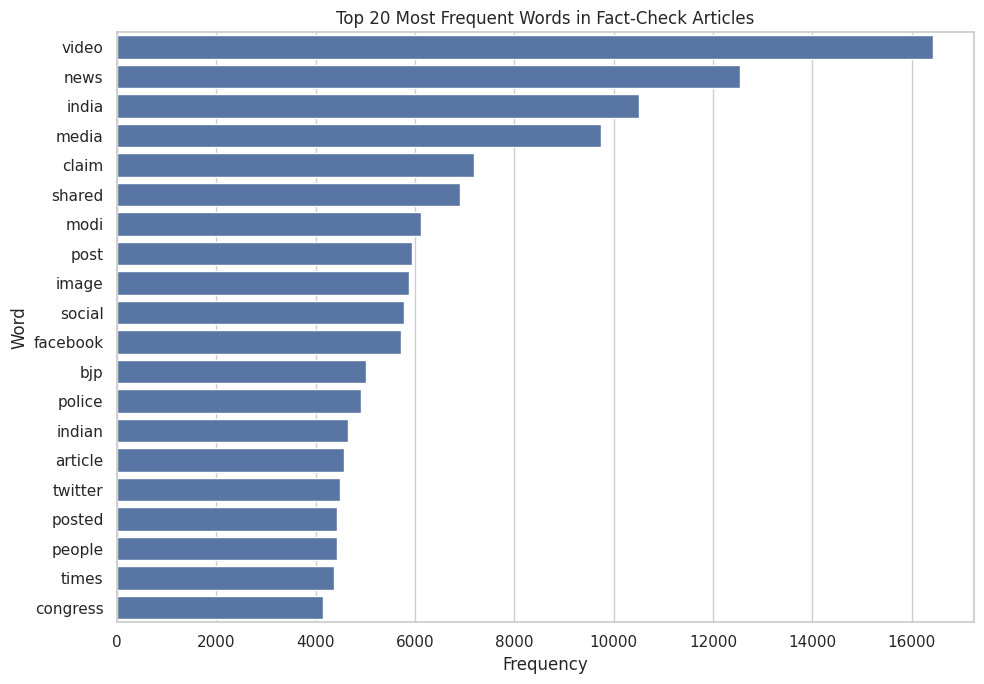

,Word,Frequency
0,video,16433
1,news,12543
2,india,10514
3,media,9737
4,claim,7195
5,shared,6915
6,modi,6128
7,post,5934
8,image,5873
9,social,5777


TF-IDF matrix shape: (4650, 3000)


,Term,Mean TF-IDF
0,video,0.040214
1,news,0.030907
2,media,0.029817
3,india,0.029439
4,claim,0.029108
5,shared,0.028175
6,post,0.026780
7,image,0.025906
8,facebook,0.025271
9,social,0.024294


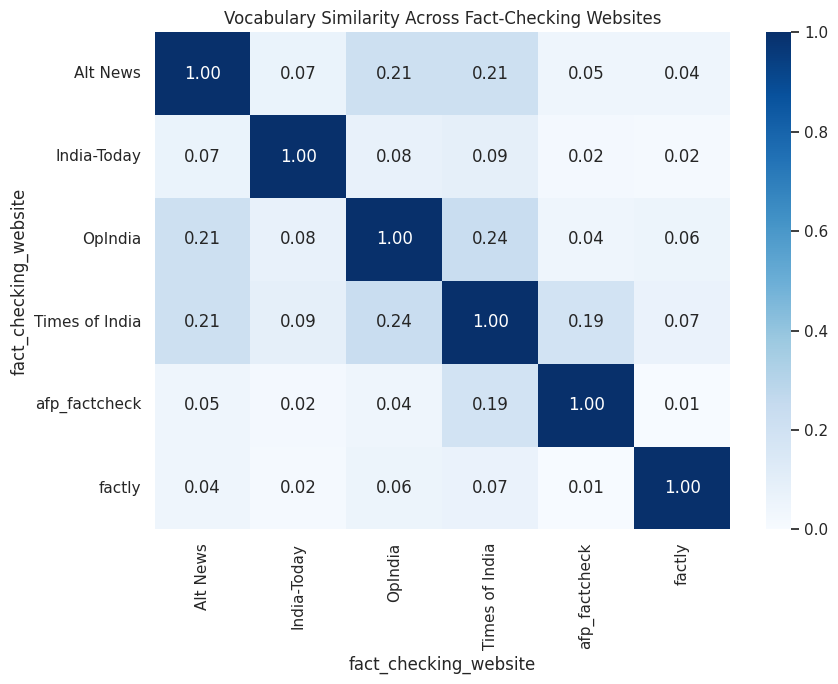

fact_checking_website,Alt News,India-Today,OpIndia,Times of India,afp_factcheck,factly
fact_checking_website,,,,,,
Alt News,1.000,0.066,0.211,0.212,0.045,0.044
India-Today,0.066,1.000,0.078,0.093,0.021,0.019
OpIndia,0.211,0.078,1.000,0.236,0.043,0.057
Times of India,0.212,0.093,0.236,1.000,0.189,0.067
afp_factcheck,0.045,0.021,0.043,0.189,1.000,0.007
factly,0.044,0.019,0.057,0.067,0.007,1.000


Discovered topics:
Topic 1: video, news, media, shared, social, police, social media, posted, alt, alt news
Topic 2: image, photo, video, facebook, post, shared, indian, published, misleading, afp
Topic 3: india, today, video, media, viral, india today, coronavirus, copyright, limited, rights
Topic 4: congress, gandhi, modi, bjp, rahul, minister, rahul gandhi, party, india, news
Topic 5: claim, post, video, information, factly, news, image, india, fact, tools
Topic 6: india, government, news, indian, article, report, fake, media, website, modi


,Article Count
Topic,
1.0,1880
2.0,401
3.0,593
4.0,621
5.0,623
6.0,532


In [8]:

import re
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.metrics.pairwise import cosine_similarity

# Prepare article text
stop_words = set(ENGLISH_STOP_WORDS)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_content"] = df["Content"].fillna("").apply(clean_text)
df["clean_title"] = df["fake_news_title"].fillna("").apply(clean_text)

# Remove stop words for exploratory word analysis
def remove_stopwords(text):
    return " ".join(
        word for word in text.split()
        if word not in stop_words and len(word) > 2
    )

df["processed_content"] = df["clean_content"].apply(remove_stopwords)

print("Sample cleaned text:")
print(df["processed_content"].iloc[0][:500])

# Most frequent words
all_words = " ".join(df["processed_content"])
word_counts = Counter(all_words.split())
top_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
)

plt.figure(figsize=(10, 7))
sns.barplot(data=top_words, x="Frequency", y="Word")
plt.title("Top 20 Most Frequent Words in Fact-Check Articles")
plt.tight_layout()
plt.show()

display(top_words)

# TF-IDF features
valid_text = df["processed_content"].str.strip().ne("")
tfidf_vectorizer = TfidfVectorizer(
    max_features=3000,
    min_df=3,
    max_df=0.90,
    ngram_range=(1, 2),
    sublinear_tf=True
)

tfidf_matrix = tfidf_vectorizer.fit_transform(
    df.loc[valid_text, "processed_content"]
)

print("TF-IDF matrix shape:", tfidf_matrix.shape)

# Most important terms by average TF-IDF
mean_tfidf = np.asarray(tfidf_matrix.mean(axis=0)).ravel()
feature_names = tfidf_vectorizer.get_feature_names_out()

top_tfidf_indices = mean_tfidf.argsort()[-20:][::-1]

top_tfidf = pd.DataFrame({
    "Term": feature_names[top_tfidf_indices],
    "Mean TF-IDF": mean_tfidf[top_tfidf_indices]
})

display(top_tfidf)

# Compare vocabulary across fact-checking outlets
outlet_texts = (
    df.groupby("fact_checking_website")["processed_content"]
      .apply(lambda texts: " ".join(texts))
)

outlet_vectorizer = TfidfVectorizer(
    max_features=2000,
    min_df=2,
    max_df=0.95
)

outlet_matrix = outlet_vectorizer.fit_transform(outlet_texts)

similarity_matrix = cosine_similarity(outlet_matrix)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=outlet_texts.index,
    columns=outlet_texts.index
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    similarity_df,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1
)
plt.title("Vocabulary Similarity Across Fact-Checking Websites")
plt.tight_layout()
plt.show()

display(similarity_df.round(3))

# Explore broad topics using LDA
topic_documents = df.loc[valid_text, "processed_content"]
topic_vectorizer = CountVectorizer(
    max_features=3000,
    min_df=5,
    max_df=0.90,
    ngram_range=(1, 2)
)

topic_matrix = topic_vectorizer.fit_transform(topic_documents)

lda = LatentDirichletAllocation(
    n_components=6,
    random_state=42,
    learning_method="batch",
    max_iter=10
)

lda.fit(topic_matrix)

topic_feature_names = topic_vectorizer.get_feature_names_out()

print("Discovered topics:")
for topic_idx, topic in enumerate(lda.components_):
    top_indices = topic.argsort()[-10:][::-1]
    terms = [topic_feature_names[i] for i in top_indices]
    print(f"Topic {topic_idx + 1}: {', '.join(terms)}")

# Assign exploratory topic labels to records with usable text
topic_probabilities = lda.transform(topic_matrix)
topic_assignments = topic_probabilities.argmax(axis=1) + 1

df["exploratory_topic"] = np.nan
df.loc[valid_text, "exploratory_topic"] = topic_assignments

topic_counts = (
    df["exploratory_topic"]
      .value_counts()
      .sort_index()
      .rename_axis("Topic")
      .to_frame("Article Count")
)

display(topic_counts)


Labeled records available: 2001

Class distribution:


,Count
Label,
Politics,1588
News,332
Science,28
Religion,26
Society,23
Education,4


Model comparison:


,Model,Accuracy,Macro F1,Weighted F1
1,Logistic Regression,0.7805,0.4099,0.7795
2,Linear SVM,0.8030,0.3779,0.7602
0,Majority Baseline,0.7930,0.1474,0.7015


Best non-baseline model by macro F1: Logistic Regression

Classification report:
              precision    recall  f1-score   support

   Education       0.00      0.00      0.00         1
        News       0.42      0.50      0.46        66
    Politics       0.87      0.86      0.87       318
    Religion       0.00      0.00      0.00         5
     Science       1.00      0.67      0.80         6
     Society       1.00      0.20      0.33         5

    accuracy                           0.78       401
   macro avg       0.55      0.37      0.41       401
weighted avg       0.79      0.78      0.78       401



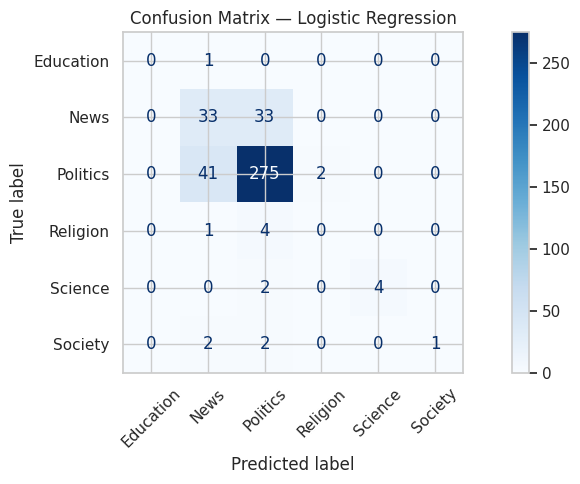

In [9]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, ConfusionMatrixDisplay,
    confusion_matrix, f1_score
)

# Keep only records with an existing topic label and usable text
ml_df = df.copy()
ml_df["Label"] = ml_df["Label"].astype("string").str.strip()

ml_df = ml_df[
    ml_df["Label"].notna()
    & ml_df["Label"].ne("")
    & ml_df["processed_content"].str.strip().ne("")
].copy()

print("Labeled records available:", len(ml_df))
print("\nClass distribution:")
display(ml_df["Label"].value_counts().to_frame("Count"))

# Remove classes with fewer than 2 records so stratified splitting is possible
class_counts = ml_df["Label"].value_counts()
ml_df = ml_df[ml_df["Label"].isin(class_counts[class_counts >= 2].index)].copy()

X = ml_df["processed_content"]
y = ml_df["Label"]

if y.nunique() < 2:
    raise ValueError("At least two topic classes are needed for classification.")

# Stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

models = {
    "Majority Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        ))
    ]),
    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("model", LinearSVC(class_weight="balanced"))
    ])
}

results = []
trained_models = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    trained_models[name] = model
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_test, y_pred, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False)

print("Model comparison:")
display(results_df.round(4))

# Detailed evaluation for the best non-baseline model
candidate_results = results_df[
    results_df["Model"] != "Majority Baseline"
]

if not candidate_results.empty:
    best_model_name = candidate_results.iloc[0]["Model"]
    best_predictions = predictions[best_model_name]

    print("Best non-baseline model by macro F1:", best_model_name)
    print("\nClassification report:")
    print(classification_report(
        y_test,
        best_predictions,
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        best_predictions,
        xticks_rotation=45,
        cmap="Blues",
        values_format="d"
    )
    plt.title(f"Confusion Matrix — {best_model_name}")
    plt.tight_layout()
    plt.show()


In [10]:

import os

os.makedirs("/kaggle/working", exist_ok=True)

# Export the cleaned dataset for the Streamlit application
df.to_csv(
    "/kaggle/working/fact_check_cleaned.csv",
    index=False,
    encoding="utf-8"
)

print("Export complete!")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("File: /kaggle/working/fact_check_cleaned.csv")


Export complete!
Rows: 4651
Columns: 19
File: /kaggle/working/fact_check_cleaned.csv


In [11]:

# Final research summary

print("INDIAN FACT-CHECKING DATASET: FINAL SUMMARY")
print("-" * 45)

print(f"Total records: {len(df):,}")
print(f"Total columns: {df.shape[1]}")
print(f"Date range: {df['fake_news_date'].min()} to {df['fake_news_date'].max()}")
print(f"Fact-checking websites: {df['fact_checking_website'].nunique()}")
print(f"Records with article text: {(df['Content'].str.strip() != '').sum():,}")
print(f"Records with missing topic labels: {df['Label'].isna().sum():,}")

print("\nTop fact-checking websites:")
display(
    df["fact_checking_website"]
    .value_counts()
    .head(10)
    .to_frame("Article Count")
)

print("\nPublication counts by year:")
year_summary = (
    df.dropna(subset=["fake_news_date"])
      .assign(year=lambda x: x["fake_news_date"].dt.year)
      .groupby("year")
      .size()
      .to_frame("Article Count")
)
display(year_summary)

print("\nMissing values:")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("Missing Values")
)

if "results_df" in globals():
    print("\nMachine learning model comparison:")
    display(results_df.round(4))

print("\nExported dataset: fact_check_cleaned.csv")


INDIAN FACT-CHECKING DATASET: FINAL SUMMARY
---------------------------------------------
Total records: 4,651
Total columns: 19
Date range: 2016-04-10 00:00:00 to 2020-02-20 00:00:00
Fact-checking websites: 6
Records with article text: 4,650
Records with missing topic labels: 2,650

Top fact-checking websites:


,Article Count
fact_checking_website,
Alt News,2002
factly,652
OpIndia,627
India-Today,608
Times of India,494
afp_factcheck,268



Publication counts by year:


,Article Count
year,
2016,16
2017,379
2018,896
2019,2922
2020,438



Missing values:


,Missing Values
Label,2650
exploratory_topic,1
fact_checking_website,0
fake_news_date,0
fake_news_url,0
facebook_post,0
fake_news_title,0
youtube_link,0
instagram_post,0
fake_news_images,0



Machine learning model comparison:


,Model,Accuracy,Macro F1,Weighted F1
1,Logistic Regression,0.7805,0.4099,0.7795
2,Linear SVM,0.8030,0.3779,0.7602
0,Majority Baseline,0.7930,0.1474,0.7015



Exported dataset: fact_check_cleaned.csv
